# 4DEnVarOcn ACC maps in 5-year blocks against the observed 1980–1995 climatology

Companion of `fair_4DEnVarOcn_acc_5yr_blocks.ipynb` **without drift correction**: the model and the observed anomalies are both taken against **the observed 1980–1995 climatology** (the mean observed seasonal value at each lead over the 1980–1995 May starts). Each experiment's lead-dependent drift and mean bias therefore stay in its anomalies and count against its ACC. Comparing with the drift-corrected notebook shows how much of the skill difference between **E3SMv3-4DEnVarOcn** and **E3SMv3-Reanalysis** comes from their drift rather than from the anomalies they predict.

The ACC is uncentred over the start years of each block (1980–1984, 1985–1989, 1990–1995) and over the full period,

ACC = Σ f′o′ / √(Σ f′² Σ o′²),  f′ = ensemble mean − observed climatology,  o′ = observation − observed climatology,

so a forecast offset from the observations (drift, bias) lowers it. Unlike in the drift-corrected notebook, the full-period column is **not** the usual Pearson ACC: the model's mean offset over 1980–1995 is included. The table also lists the RMS block-mean offset (forecast minus observation, area RMS) to show how large that drift is.

Every figure is drawn twice (`DETREND_OPTIONS`): with a linear trend over 1980–1995 removed from both anomalies (the slope only: the mean offset, i.e. the drift, is kept; file tag `detrend`), and without detrending (`nodetrend`).

**Caution.** A block has only 5–6 start years; read the maps for large-scale patterns and the area-mean values in the panel labels.

Inputs are only read: the 1a prepared caches with the 1980–1995 climatology (raw field = cached anomaly + cached climatology) and the prepared observations, under the test diagnostic root.


In [1]:
# Test-run output roots (set before importing esp_lab so every module sees them).
import os
os.environ["ESP_LAB_FIGURE_ROOT"] = "/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures"
os.environ["ESP_LAB_S2D_DIAG_ROOT"] = "/global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test"
os.environ["ESP_LAB_FIGURE_GALLERY"] = "0"  # test runs: figures only, no figures.json/index.html

%matplotlib inline
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

from esp_lab import env_paths
from esp_lab import sample_size_skill as sss
from esp_lab.leadtime_plot_utils import add_lead_badge, style_global_map_axis
from esp_lab.utils import mapplot_utils as maps
from esp_lab.utils.filename_utils import figure_filename
from workflows.diagnostics.sample_size import lead_labels

Warning 3: Cannot find header.dxf (GDAL_DATA is not defined)
ERROR 1: PROJ: proj_create_from_database: Cannot find proj.db


In [2]:
# =============================================================================
# CONFIGURATION BLOCK: Edit settings here
# =============================================================================
INIT_MONTH = 5
CLIMATOLOGY_YEARS = (1980, 1995)          # observed climatology removed from model and observations
BLOCKS = [(1980, 1984), (1985, 1989), (1990, 1995)]
SHOW_FULL_PERIOD = True                   # add the full climatology period as a reference column
DETREND_OPTIONS = [True, False]           # True: remove one linear trend over CLIMATOLOGY_YEARS first

FIELDS = ["TS", "TREFHT", "PRECT", "PSL"]
PLOT_LEADS = ["JJA0", "DJF1", "JJA1"]     # one figure per field and lead (labels: season + years after start)

# Experiment, control and the difference row (experiment minus control).
EXPERIMENT = dict(tag="4DEnVarOcn", label="E3SMv3-4DEnVarOcn")
CONTROL = dict(tag="Reanalysis", label="E3SMv3-Reanalysis")
OBS_NAME = {"TS": "ERA5", "TREFHT": "ERA5", "PRECT": "GPCP v2.3", "PSL": "ERA5"}

ACC_LEVELS = (-1.0, 1.0, 0.1)             # (min, max, interval) of the ACC colour scale
DIFF_LEVELS = (-0.8, 0.8, 0.1)            # same for the difference row
AREA_LATLIM = 80                          # |lat| limit of the area-mean ACC in the panel labels
FIGURE_SET = "4DEnVarOcn_5yr_blocks_obsclim"      # figures go to <figure root>/<FIGURE_SET>/
# ===== END CONFIGURATION BLOCK =====

DIAG_ROOT = env_paths.s2d_diag_root()
FIGURE_DIR = env_paths.figure_root() / FIGURE_SET
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
y0, y1 = CLIMATOLOGY_YEARS
print(f"Diagnostics: {DIAG_ROOT}\nFigures: {FIGURE_DIR}")

Diagnostics: /global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test
Figures: /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/4DEnVarOcn_5yr_blocks_obsclim


## Inputs

Raw model ensemble means (cached anomaly + cached drift climatology) and the prepared observations at each verification season; both minus the observed mean over the 1980–1995 start years.

In [3]:
def prepared_path(tag, field):
    folder = DIAG_ROOT / tag / "leadtime_acc" / "prepared_skill" / "atm" / field
    name = (f"{tag}_init{INIT_MONTH:02d}_{field}_seasonal_anomaly_y{y0}-{y1}_ny{y1 - y0 + 1}"
            f"_clim_{y0}_{y1}_m*_l*_5x5deg_skill_v1.nc")
    found = sorted(folder.glob(name))
    if len(found) != 1:
        raise FileNotFoundError(f"expected one prepared cache {folder / name}, found {len(found)}")
    return found[0]


def observed_at(field, valid_time):
    """Observed seasonal values (Y, L, lat, lon) at each verification season."""
    folder = DIAG_ROOT / "observations" / "leadtime_acc" / "prepared_skill" / "atm" / field
    obs = xr.open_dataset(sorted(folder.glob(f"*_{field}_seasonal_5x5deg_skill_v1.nc"))[0])["observation"]
    return sss.observations_at_valid_time(obs, valid_time)


def detrend(anom):
    """Remove the least-squares linear trend in start year but keep the mean (the drift/bias)."""
    t = xr.DataArray(sss.init_years(anom.Y.values).astype(float), dims="Y", coords={"Y": anom.Y})
    t = t - t.mean()
    slope = ((anom - anom.mean("Y")) * t).sum("Y") / (t ** 2).sum()
    return anom - slope * t


def load_field(field, detrend_anomalies):
    """{label: ensemble-mean anomaly} for experiment and control, plus the observed anomaly."""
    data, valid_time = {}, None
    for case in (EXPERIMENT, CONTROL):
        ds = xr.open_dataset(prepared_path(case["tag"], field))
        if (int(ds.attrs["climatology_start_year"]), int(ds.attrs["climatology_end_year"])) != CLIMATOLOGY_YEARS:
            raise ValueError(f"{case['tag']} {field}: cache climatology is not {CLIMATOLOGY_YEARS}")
        data[case["label"]] = (ds["anomaly"] + ds["climatology"]).mean("M").load()   # raw ensemble mean
        valid_time = ds["time"] if valid_time is None else valid_time
    observed = observed_at(field, valid_time)
    obs_clim = observed.mean("Y")                       # observed climatology for every lead
    data = {label: raw - obs_clim for label, raw in data.items()}
    obs = observed - obs_clim
    labels = lead_labels(valid_time)
    if detrend_anomalies:
        data = {k: detrend(v) for k, v in data.items()}
        obs = detrend(obs)
    return data, obs, labels


def uncentred_acc(fcst, obs, years):
    """ACC from anomalies against the fixed climatology over the start years ``years``."""
    sel = np.isin(sss.init_years(fcst.Y.values), np.arange(years[0], years[1] + 1))
    f, o = fcst.isel(Y=sel), obs.isel(Y=sel)
    complete = (f.notnull() & o.notnull()).all("Y")
    acc = (f * o).sum("Y") / np.sqrt((f ** 2).sum("Y") * (o ** 2).sum("Y"))
    return acc.where(complete & np.isfinite(acc))


def rms_offset(fcst, obs, years):
    """Area RMS (|lat| < AREA_LATLIM) of the block-mean forecast-minus-observation offset, per lead."""
    sel = np.isin(sss.init_years(fcst.Y.values), np.arange(years[0], years[1] + 1))
    offset = (fcst.isel(Y=sel) - obs.isel(Y=sel)).mean("Y")
    w = np.cos(np.deg2rad(offset.lat)).where(abs(offset.lat) < AREA_LATLIM)
    return np.sqrt((offset ** 2).weighted(w.fillna(0)).mean(("lat", "lon")))


def area_mean(acc):
    w = np.cos(np.deg2rad(acc.lat)).where(abs(acc.lat) < AREA_LATLIM)
    return float(acc.weighted(w.fillna(0)).mean(("lat", "lon")))

## Block ACC

For every field: the uncentred ACC of the experiment and the control in each block (and over the full period), and their difference. The table lists the area-mean ACC (cos-latitude weighted, |lat| < 80°) per block and the RMS block-mean offset (forecast minus observation; the drift and bias that the observed climatology leaves in).

In [4]:
COLUMNS = list(BLOCKS) + ([CLIMATOLOGY_YEARS] if SHOW_FULL_PERIOD else [])
results, rows = {}, []
for detrended in DETREND_OPTIONS:
    for field in FIELDS:
        data, obs, labels = load_field(field, detrended)
        acc = {(label, years): uncentred_acc(fcst, obs, years) for label, fcst in data.items() for years in COLUMNS}
        offset = {(label, years): rms_offset(fcst, obs, years) for label, fcst in data.items() for years in COLUMNS}
        results[(field, detrended)] = dict(acc=acc, labels=labels)
        for (label, years), a in acc.items():
            for lead, name in zip(a.L.values, labels):
                rows.append(dict(field=field, detrend=detrended, experiment=label, years=f"{years[0]}-{years[1]}",
                                 lead=name, area_mean_acc=area_mean(a.sel(L=lead)),
                                 rms_offset=float(offset[(label, years)].sel(L=lead))))
        print(f"done: {field} ({'detrended' if detrended else 'not detrended'})")
summary = pd.DataFrame(rows)
summary.to_csv(FIGURE_DIR / f"acc_5yr_blocks_{EXPERIMENT['tag']}_vs_{CONTROL['tag']}_obsclim{y0}-{y1}.csv", index=False)
(summary[summary.lead.isin(PLOT_LEADS)]
 .pivot_table(index=["detrend", "field", "lead", "experiment"], columns="years",
              values=["area_mean_acc", "rms_offset"], sort=False).round(2))

done: TS (detrended)


done: TREFHT (detrended)


done: PRECT (detrended)


done: PSL (detrended)


done: TS (not detrended)


done: TREFHT (not detrended)


done: PRECT (not detrended)


done: PSL (not detrended)


area_mean_acc                      \
years                                     1980-1984 1985-1989 1990-1995   
detrend field  lead experiment                                            
True    TS     JJA0 E3SMv3-4DEnVarOcn          0.09      0.12      0.06   
                    E3SMv3-Reanalysis          0.25      0.22      0.25   
               DJF1 E3SMv3-4DEnVarOcn          0.13      0.04      0.02   
                    E3SMv3-Reanalysis          0.08      0.10      0.07   
               JJA1 E3SMv3-4DEnVarOcn          0.04      0.05      0.02   
                    E3SMv3-Reanalysis          0.03      0.08      0.04   
        TREFHT JJA0 E3SMv3-4DEnVarOcn          0.08      0.11      0.07   
                    E3SMv3-Reanalysis          0.23      0.18      0.22   
               DJF1 E3SMv3-4DEnVarOcn          0.13      0.06      0.02   
                    E3SMv3-Reanalysis          0.07      0.09      0.07   
               JJA1 E3SMv3-4DEnVarOcn          0.03      0.06      0.02   
                    E3SMv3-Reanalysis          0.03      0.08      0.04   
        PRECT  JJA0 E3SMv3-4DEnVarOcn          0.10      0.07      0.01   
                    E3SMv3-Reanalysis          0.12      0.10      0.08   
               DJF1 E3SMv3-4DEnVarOcn          0.11      0.00      0.01   
                    E3SMv3-Reanalysis          0.07     -0.01      0.04   
               JJA1 E3SMv3-4DEnVarOcn          0.05     -0.03      0.01   
                    E3SMv3-Reanalysis          0.04     -0.01      0.03   
        PSL    JJA0 E3SMv3-4DEnVarOcn          0.06      0.05      0.01   
                    E3SMv3-Reanalysis          0.05      0.08      0.10   
               DJF1 E3SMv3-4DEnVarOcn          0.18      0.18     -0.01   
                    E3SMv3-Reanalysis          0.05      0.14      0.07   
               JJA1 E3SMv3-4DEnVarOcn          0.04     -0.04     -0.02   
                    E3SMv3-Reanalysis          0.02      0.07     -0.03   
False   TS     JJA0 E3SMv3-4DEnVarOcn          0.02      0.12      0.12   
                    E3SMv3-Reanalysis          0.18      0.22      0.31   
               DJF1 E3SMv3-4DEnVarOcn          0.12      0.04      0.02   
                    E3SMv3-Reanalysis          0.07      0.09      0.09   
               JJA1 E3SMv3-4DEnVarOcn         -0.04      0.05      0.10   
                    E3SMv3-Reanalysis         -0.03      0.07      0.12   
        TREFHT JJA0 E3SMv3-4DEnVarOcn         -0.01      0.11      0.15   
                    E3SMv3-Reanalysis          0.16      0.18      0.29   
               DJF1 E3SMv3-4DEnVarOcn          0.11      0.06      0.03   
                    E3SMv3-Reanalysis          0.05      0.09      0.10   
               JJA1 E3SMv3-4DEnVarOcn         -0.05      0.05      0.11   
                    E3SMv3-Reanalysis         -0.05      0.08      0.13   
        PRECT  JJA0 E3SMv3-4DEnVarOcn          0.09      0.07      0.00   
                    E3SMv3-Reanalysis          0.11      0.09      0.07   
               DJF1 E3SMv3-4DEnVarOcn          0.11      0.00     -0.02   
                    E3SMv3-Reanalysis          0.08     -0.01      0.01   
               JJA1 E3SMv3-4DEnVarOcn          0.05     -0.03     -0.01   
                    E3SMv3-Reanalysis          0.03     -0.01      0.02   
        PSL    JJA0 E3SMv3-4DEnVarOcn          0.03      0.05      0.07   
                    E3SMv3-Reanalysis          0.02      0.07      0.15   
               DJF1 E3SMv3-4DEnVarOcn          0.15      0.17      0.06   
                    E3SMv3-Reanalysis          0.01      0.13      0.15   
               JJA1 E3SMv3-4DEnVarOcn         -0.02     -0.04      0.05   
                    E3SMv3-Reanalysis         -0.03      0.07      0.05   

                                                rms_offset            \
years                                 1980-1995  1980-1984 1985-1989   
detrend field  lead experiment                                      

## Maps

Rows: experiment, control, experiment minus control. Columns: the 5-year blocks and the full period. Each panel label gives the area-mean ACC (or ACC difference).

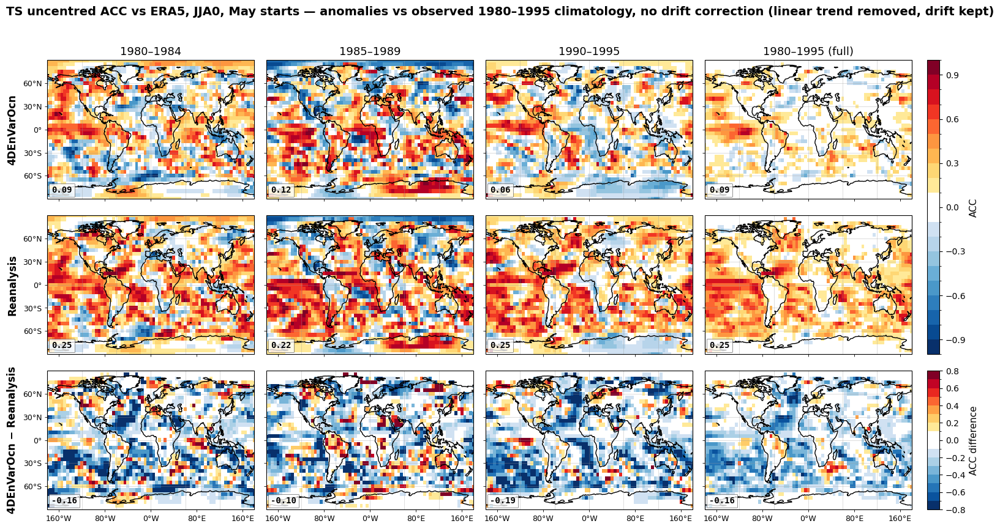

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/4DEnVarOcn_5yr_blocks_obsclim/fig_acc_5yr_blocks_4denvarocn_vs_reanalysis_ts_init05_jja0_obsclim1980_1995_detrend.png


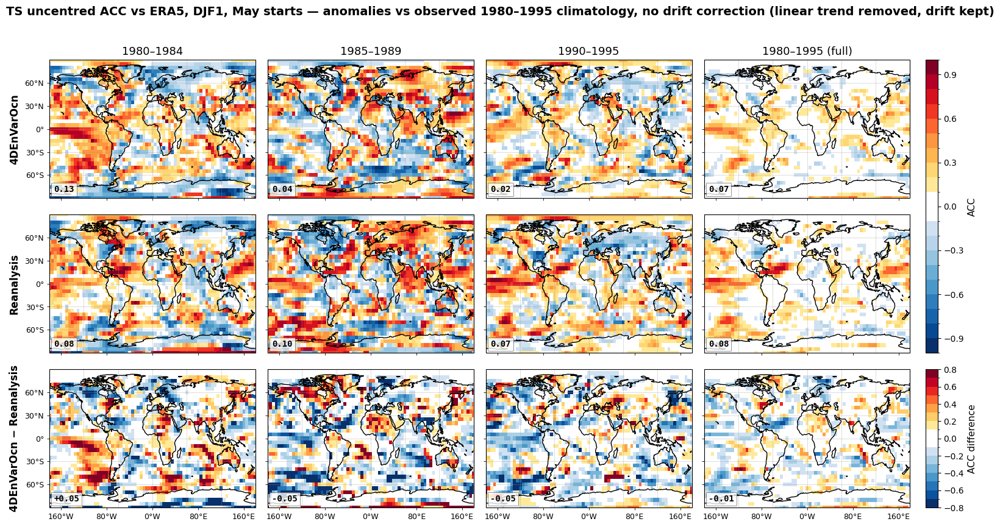

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/4DEnVarOcn_5yr_blocks_obsclim/fig_acc_5yr_blocks_4denvarocn_vs_reanalysis_ts_init05_djf1_obsclim1980_1995_detrend.png


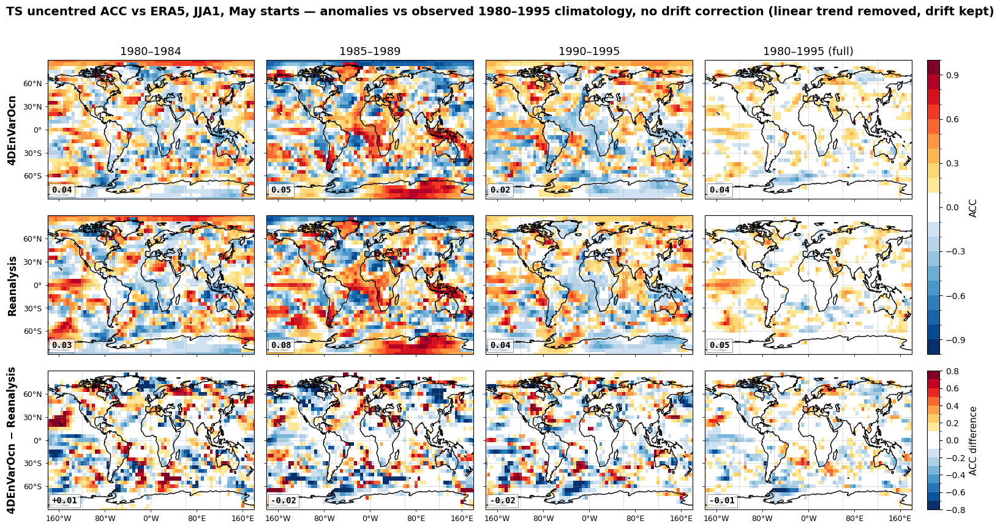

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/4DEnVarOcn_5yr_blocks_obsclim/fig_acc_5yr_blocks_4denvarocn_vs_reanalysis_ts_init05_jja1_obsclim1980_1995_detrend.png


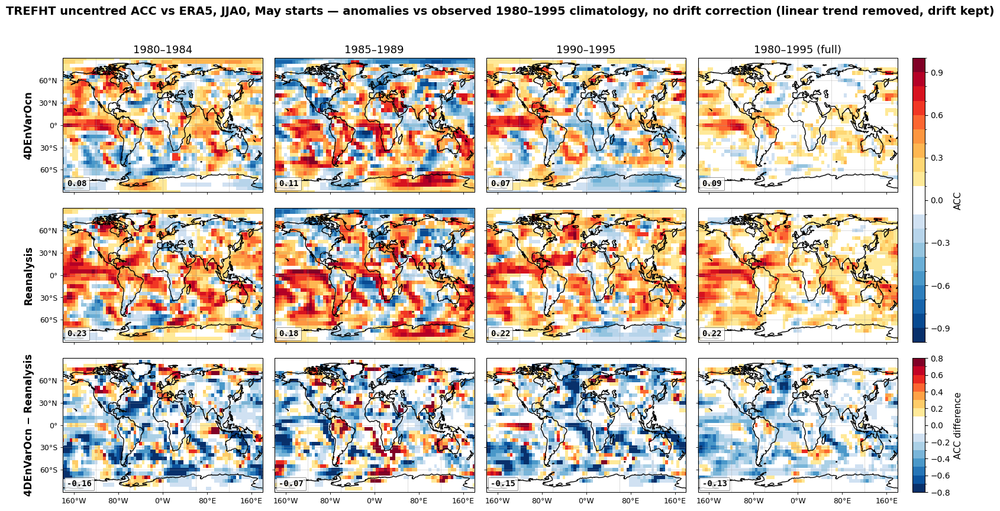

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/4DEnVarOcn_5yr_blocks_obsclim/fig_acc_5yr_blocks_4denvarocn_vs_reanalysis_trefht_init05_jja0_obsclim1980_1995_detrend.png


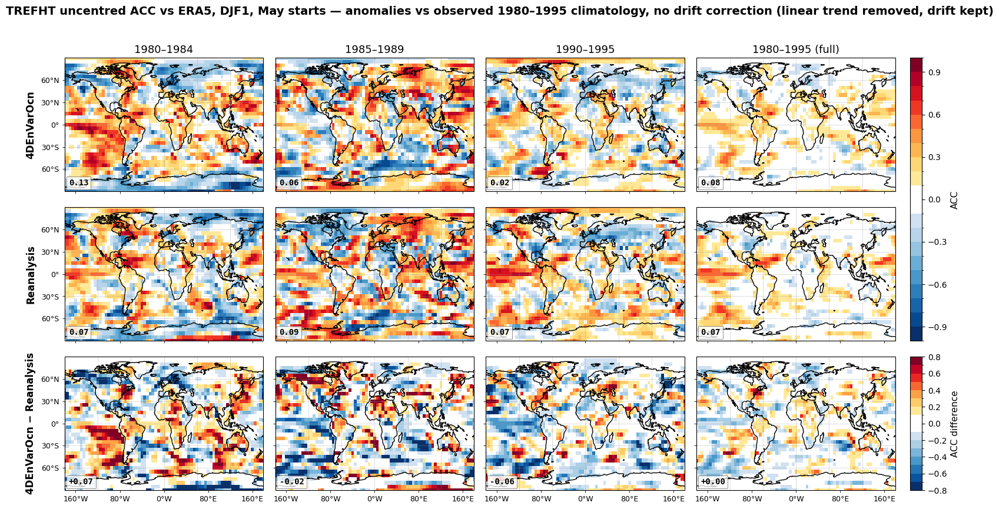

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/4DEnVarOcn_5yr_blocks_obsclim/fig_acc_5yr_blocks_4denvarocn_vs_reanalysis_trefht_init05_djf1_obsclim1980_1995_detrend.png


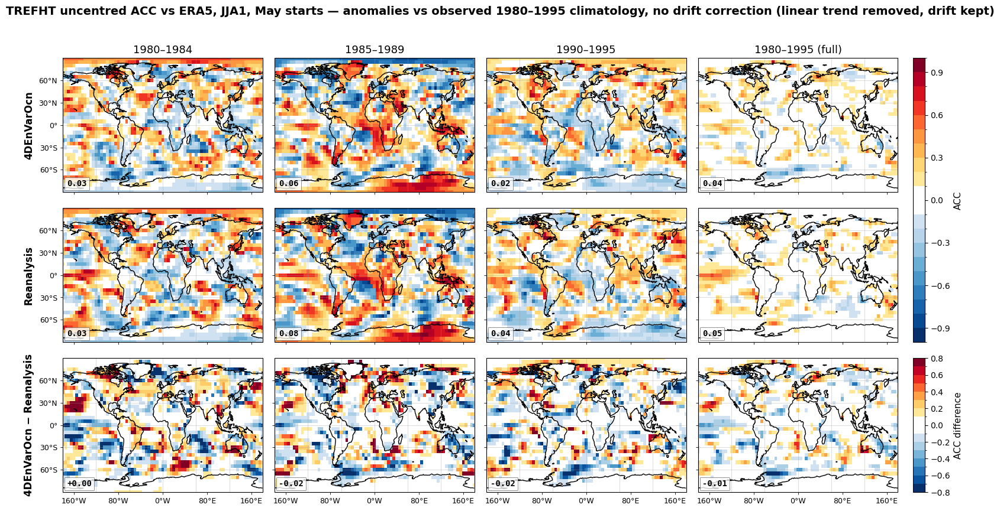

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/4DEnVarOcn_5yr_blocks_obsclim/fig_acc_5yr_blocks_4denvarocn_vs_reanalysis_trefht_init05_jja1_obsclim1980_1995_detrend.png


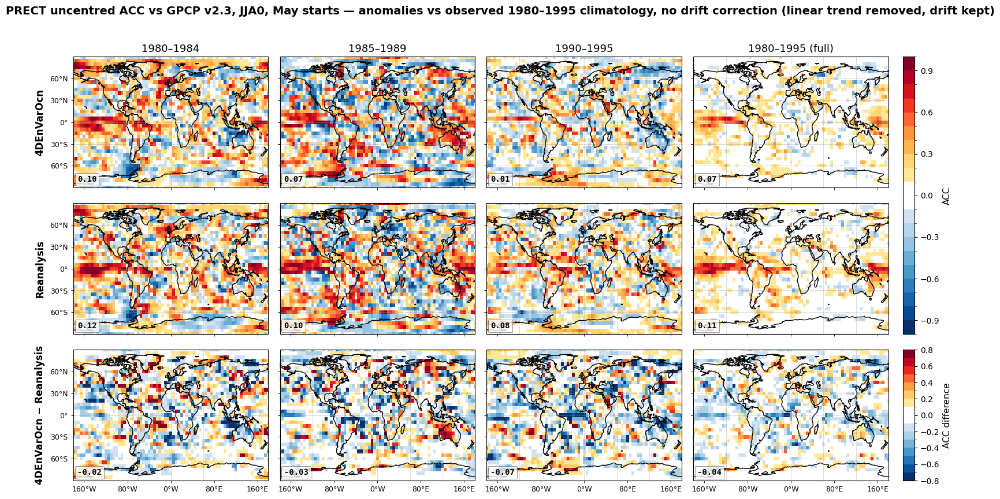

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/4DEnVarOcn_5yr_blocks_obsclim/fig_acc_5yr_blocks_4denvarocn_vs_reanalysis_prect_init05_jja0_obsclim1980_1995_detrend.png


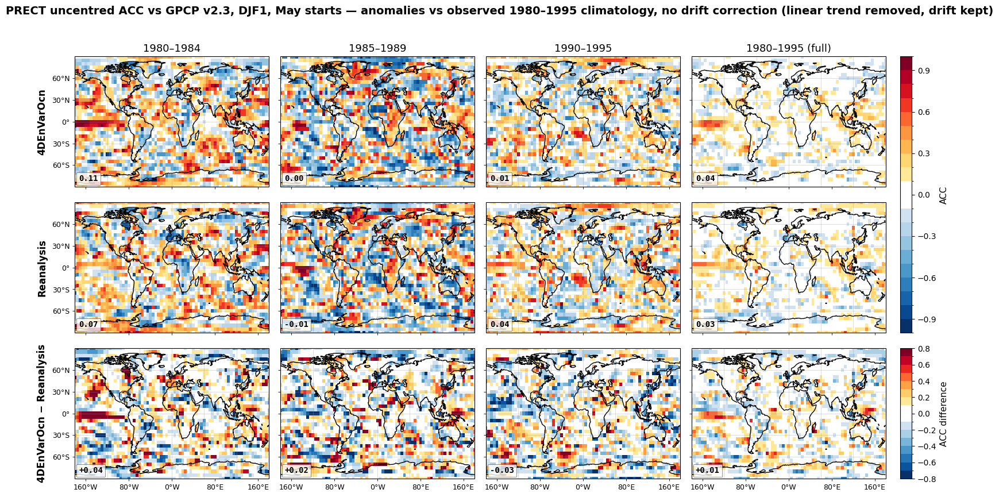

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/4DEnVarOcn_5yr_blocks_obsclim/fig_acc_5yr_blocks_4denvarocn_vs_reanalysis_prect_init05_djf1_obsclim1980_1995_detrend.png


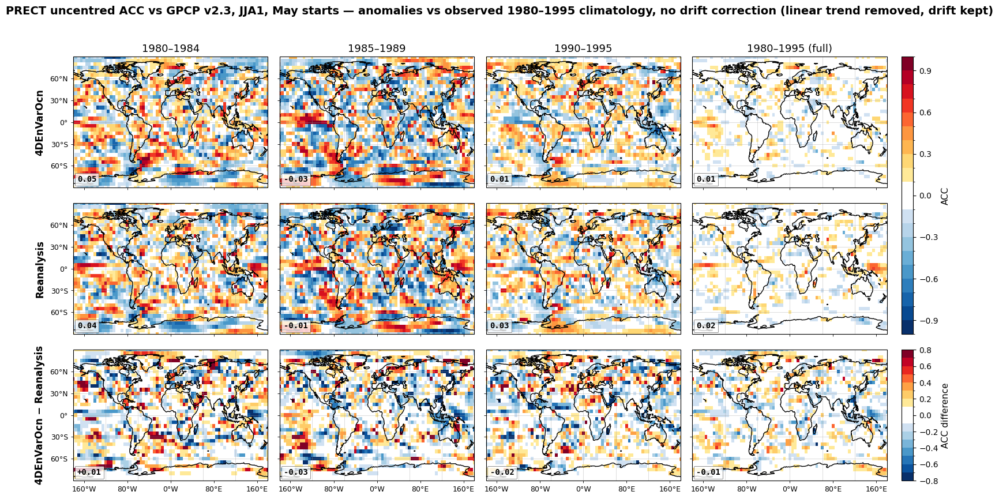

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/4DEnVarOcn_5yr_blocks_obsclim/fig_acc_5yr_blocks_4denvarocn_vs_reanalysis_prect_init05_jja1_obsclim1980_1995_detrend.png


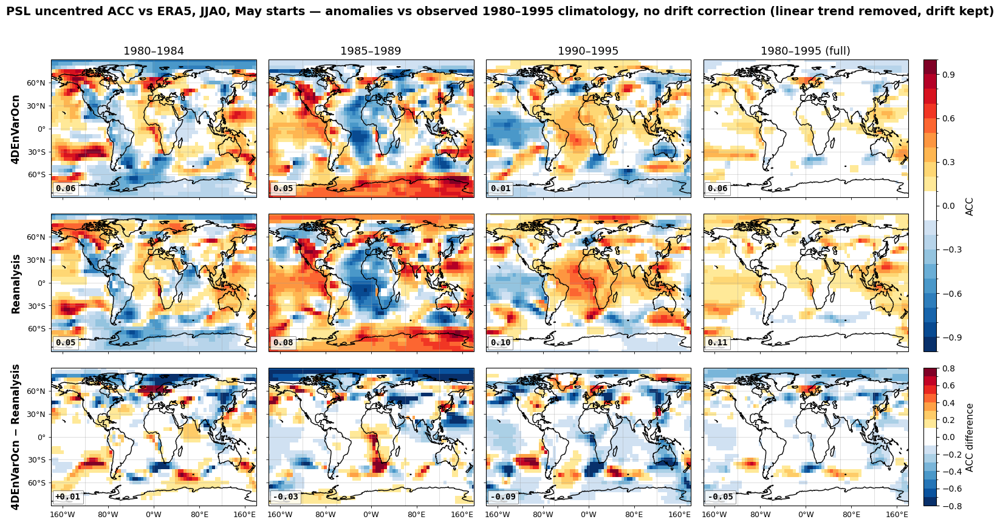

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/4DEnVarOcn_5yr_blocks_obsclim/fig_acc_5yr_blocks_4denvarocn_vs_reanalysis_psl_init05_jja0_obsclim1980_1995_detrend.png


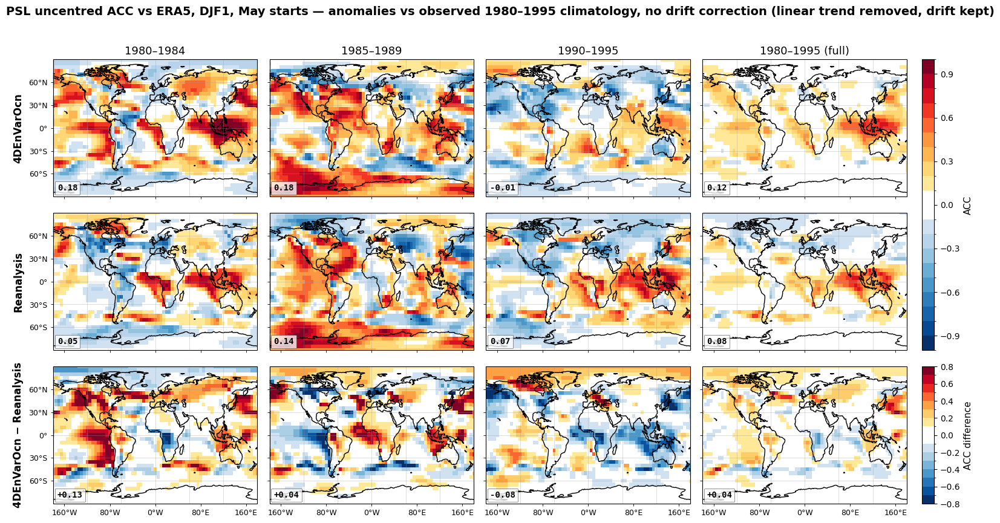

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/4DEnVarOcn_5yr_blocks_obsclim/fig_acc_5yr_blocks_4denvarocn_vs_reanalysis_psl_init05_djf1_obsclim1980_1995_detrend.png


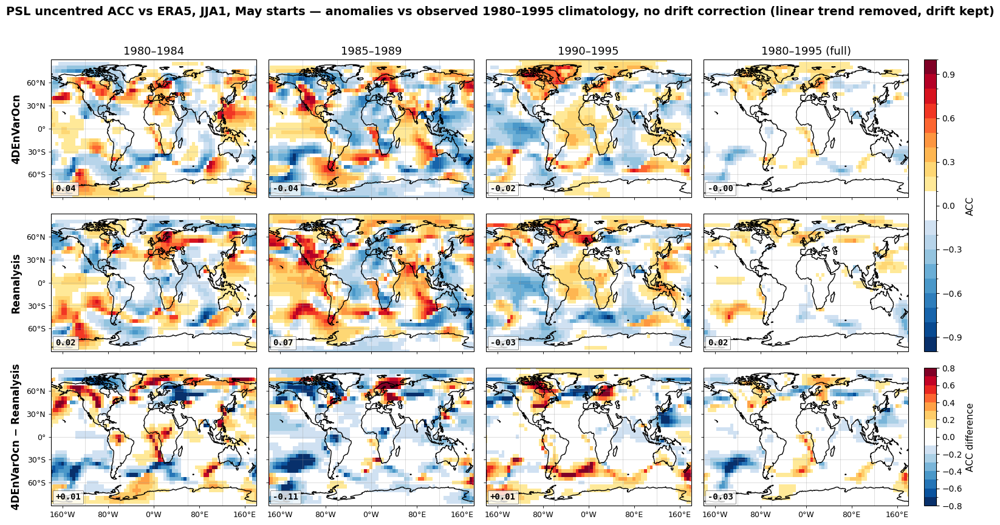

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/4DEnVarOcn_5yr_blocks_obsclim/fig_acc_5yr_blocks_4denvarocn_vs_reanalysis_psl_init05_jja1_obsclim1980_1995_detrend.png


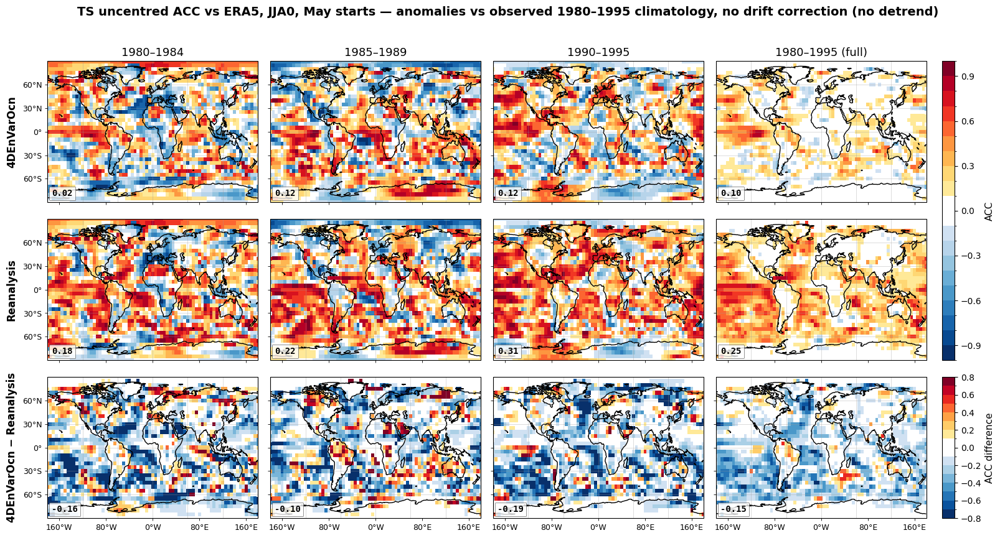

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/4DEnVarOcn_5yr_blocks_obsclim/fig_acc_5yr_blocks_4denvarocn_vs_reanalysis_ts_init05_jja0_obsclim1980_1995_nodetrend.png


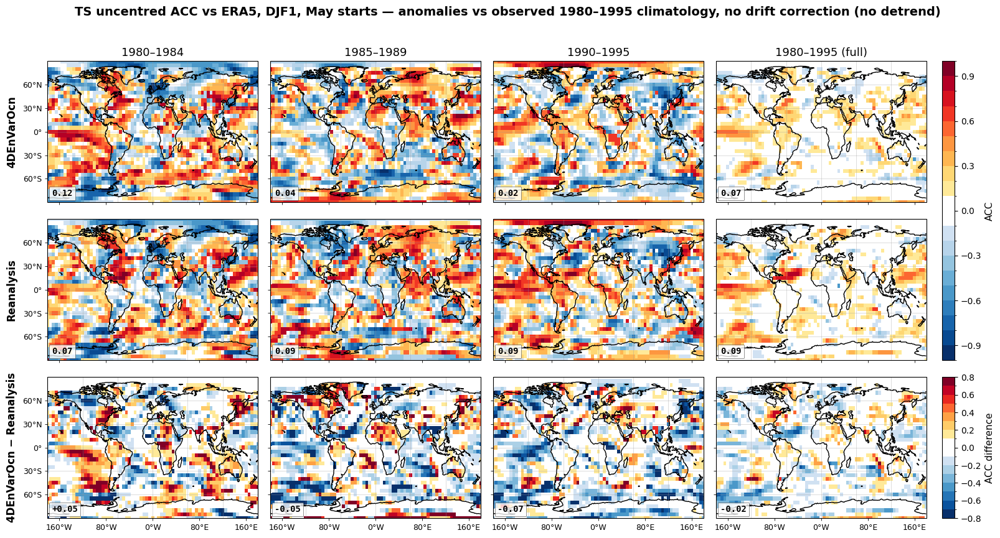

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/4DEnVarOcn_5yr_blocks_obsclim/fig_acc_5yr_blocks_4denvarocn_vs_reanalysis_ts_init05_djf1_obsclim1980_1995_nodetrend.png


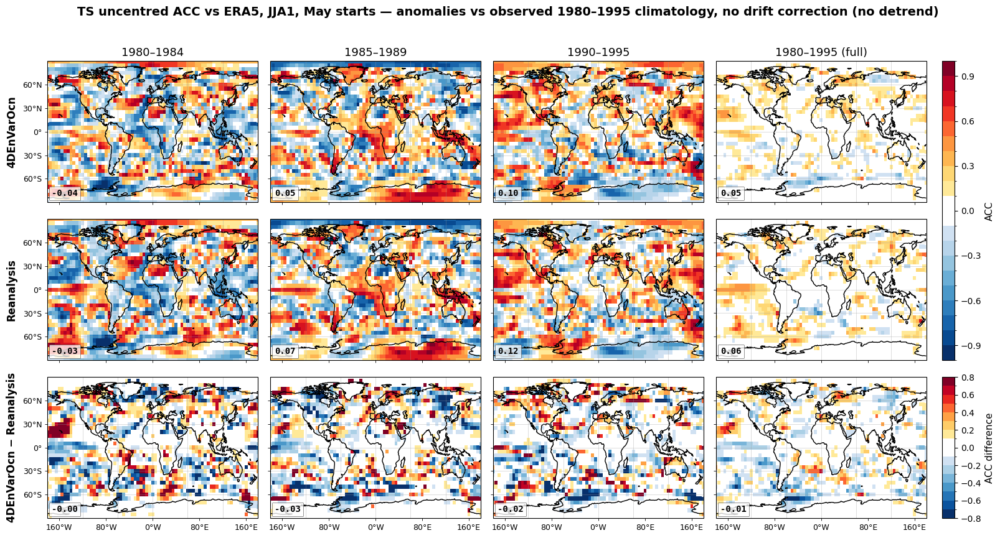

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/4DEnVarOcn_5yr_blocks_obsclim/fig_acc_5yr_blocks_4denvarocn_vs_reanalysis_ts_init05_jja1_obsclim1980_1995_nodetrend.png


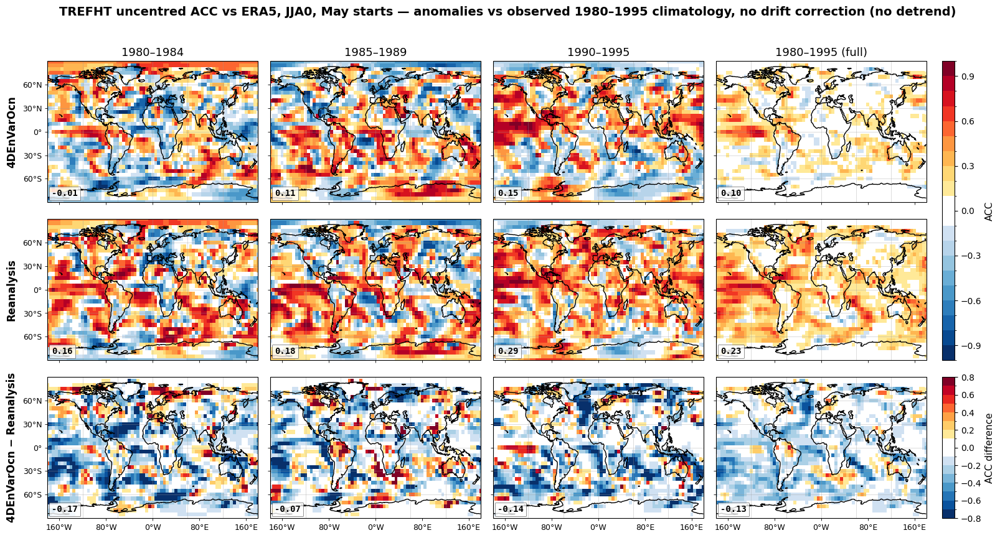

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/4DEnVarOcn_5yr_blocks_obsclim/fig_acc_5yr_blocks_4denvarocn_vs_reanalysis_trefht_init05_jja0_obsclim1980_1995_nodetrend.png


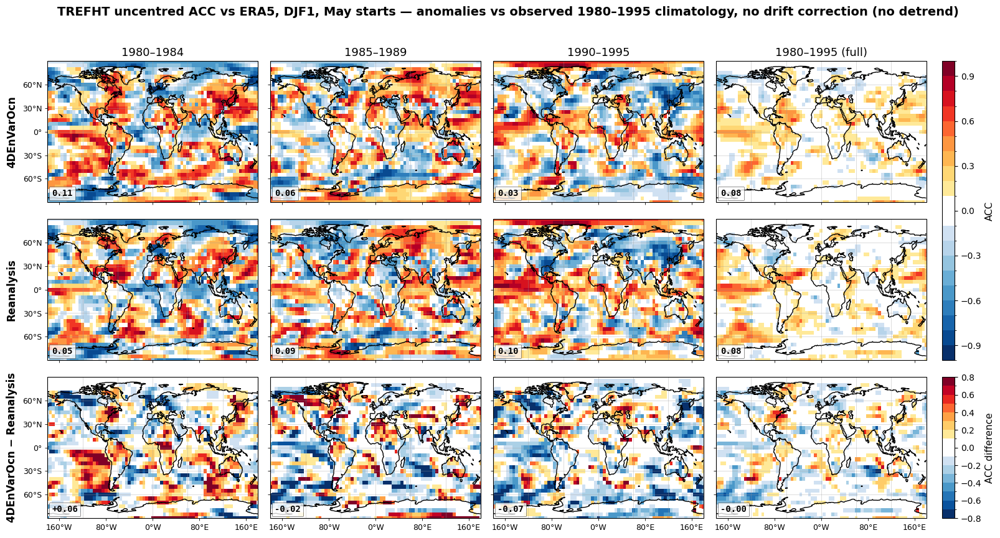

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/4DEnVarOcn_5yr_blocks_obsclim/fig_acc_5yr_blocks_4denvarocn_vs_reanalysis_trefht_init05_djf1_obsclim1980_1995_nodetrend.png


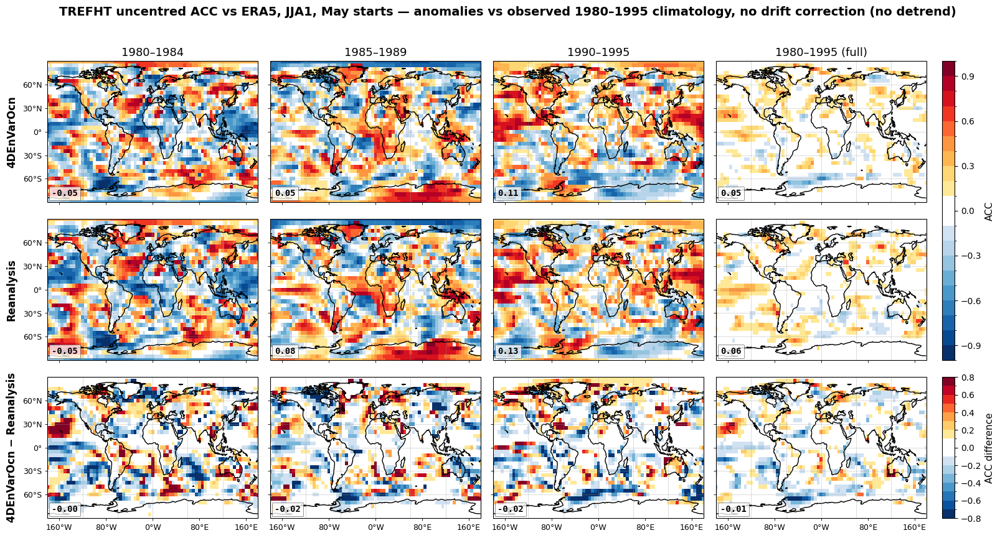

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/4DEnVarOcn_5yr_blocks_obsclim/fig_acc_5yr_blocks_4denvarocn_vs_reanalysis_trefht_init05_jja1_obsclim1980_1995_nodetrend.png


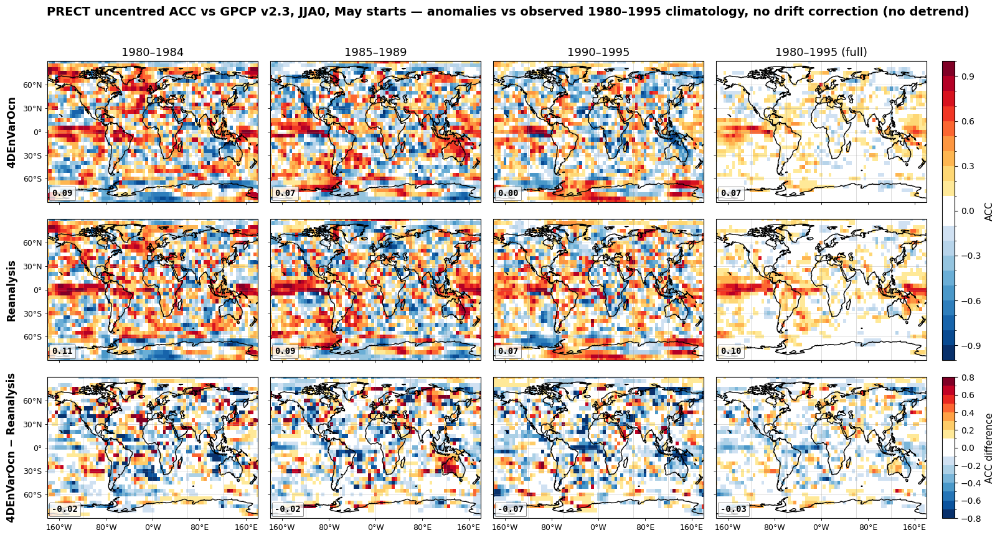

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/4DEnVarOcn_5yr_blocks_obsclim/fig_acc_5yr_blocks_4denvarocn_vs_reanalysis_prect_init05_jja0_obsclim1980_1995_nodetrend.png


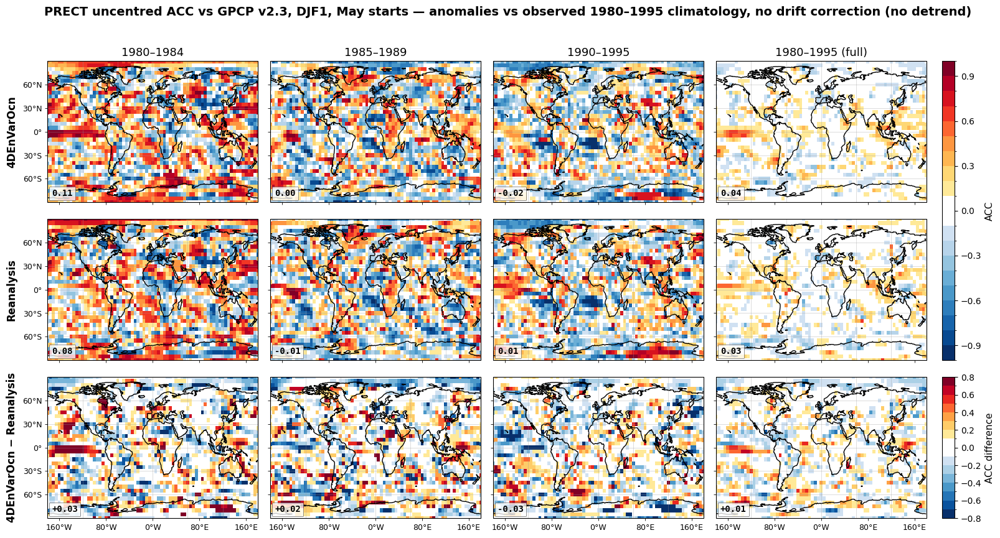

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/4DEnVarOcn_5yr_blocks_obsclim/fig_acc_5yr_blocks_4denvarocn_vs_reanalysis_prect_init05_djf1_obsclim1980_1995_nodetrend.png


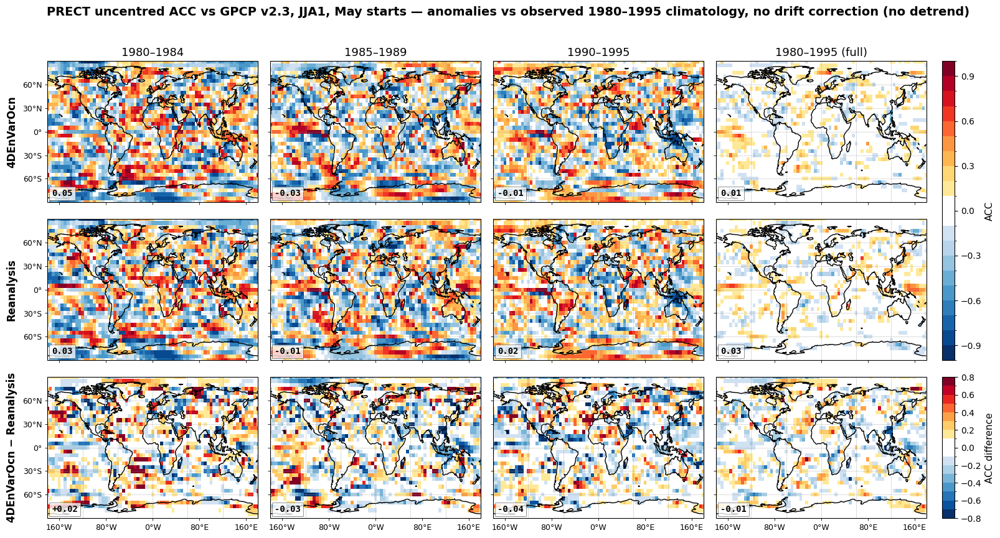

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/4DEnVarOcn_5yr_blocks_obsclim/fig_acc_5yr_blocks_4denvarocn_vs_reanalysis_prect_init05_jja1_obsclim1980_1995_nodetrend.png


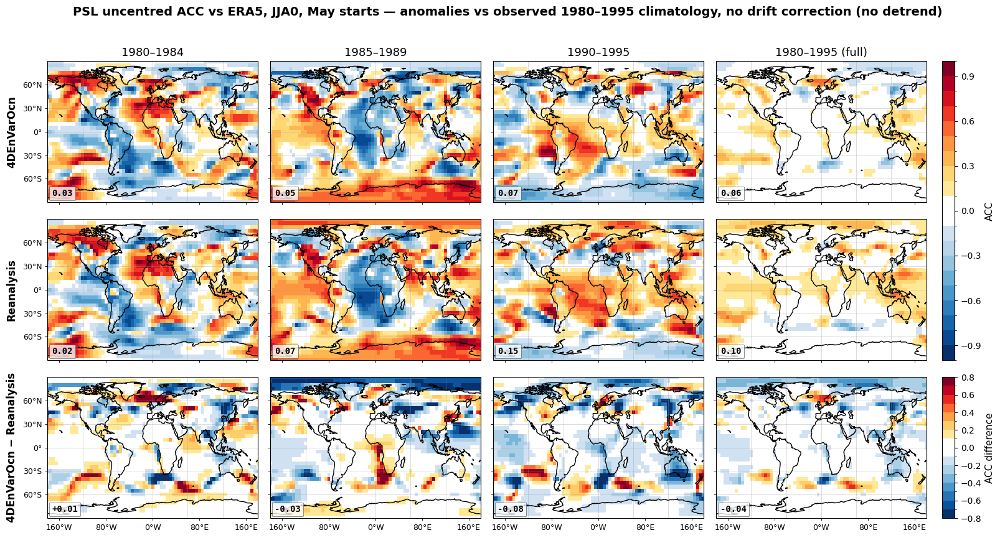

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/4DEnVarOcn_5yr_blocks_obsclim/fig_acc_5yr_blocks_4denvarocn_vs_reanalysis_psl_init05_jja0_obsclim1980_1995_nodetrend.png


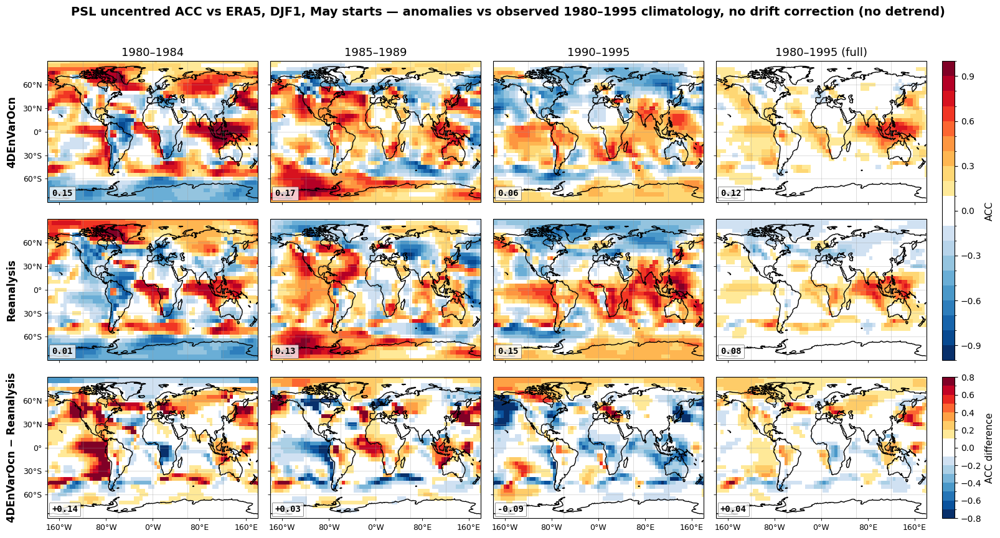

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/4DEnVarOcn_5yr_blocks_obsclim/fig_acc_5yr_blocks_4denvarocn_vs_reanalysis_psl_init05_djf1_obsclim1980_1995_nodetrend.png


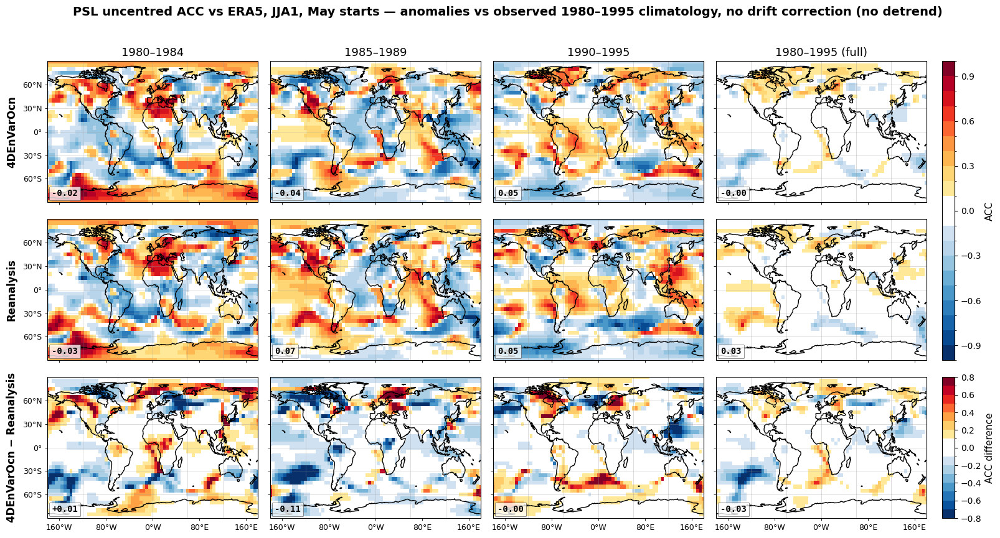

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/4DEnVarOcn_5yr_blocks_obsclim/fig_acc_5yr_blocks_4denvarocn_vs_reanalysis_psl_init05_jja1_obsclim1980_1995_nodetrend.png


In [5]:
PROJECTION = ccrs.PlateCarree()
MAP_STYLE = dict(lon_ticks=[-160, -80, 0, 80, 160], lat_ticks=[-60, -30, 0, 30, 60],
                 tick_length=3, tick_width=0.6, grid_linewidth=0.4, grid_color="0.6", grid_alpha=0.6)


def plot_blocks(field, lead_name, detrended):
    res = results[(field, detrended)]
    lead = res["acc"][(EXPERIMENT["label"], COLUMNS[0])].L.values[res["labels"].index(lead_name)]
    row_specs = [(EXPERIMENT["label"], "acc"), (CONTROL["label"], "acc"),
                 (f"{EXPERIMENT['label']} − {CONTROL['label'].replace('E3SMv3-', '')}", "diff")]
    nrows, ncols = len(row_specs), len(COLUMNS)
    fig = plt.figure(figsize=(4.2 * ncols, 2.55 * nrows + 1.2))
    mappables = {}
    for r, (row_label, kind) in enumerate(row_specs):
        for c, years in enumerate(COLUMNS):
            exp = res["acc"][(EXPERIMENT["label"], years)].sel(L=lead)
            ctl = res["acc"][(CONTROL["label"], years)].sel(L=lead)
            panel = {0: exp, 1: ctl, 2: exp - ctl}[r]
            vmin, vmax, step = ACC_LEVELS if kind == "acc" else DIFF_LEVELS
            title = (f"{years[0]}–{years[1]}" + (" (full)" if years == CLIMATOLOGY_YEARS else "")) if r == 0 else ""
            ax, mappables[kind] = maps.map_pcolor_global_subplot(
                fig, panel, panel.lon, panel.lat, step, vmin, vmax, title, nrows, ncols,
                r * ncols + c + 1, PROJECTION, fontsize=13)
            style_global_map_axis(ax, row=r, column=c, nrows=nrows, label_size=9, style=MAP_STYLE)
            sign = "+" if kind == "diff" else ""
            add_lead_badge(ax, f"{area_mean(panel):{sign}.2f}", font_size=10, location="lower left")
            if c == 0:
                ax.text(-0.17, 0.5, row_label.replace("E3SMv3-", ""), transform=ax.transAxes, rotation=90,
                        ha="center", va="center", fontsize=12, fontweight="bold")
    fig.subplots_adjust(left=0.06, right=0.9, top=0.88, bottom=0.05, wspace=0.06, hspace=0.12)
    for kind, label, rows_ in (("acc", "ACC", (0, 1)), ("diff", "ACC difference", (2,))):
        top = fig.axes[rows_[0] * ncols].get_position().y1
        bottom = fig.axes[rows_[-1] * ncols].get_position().y0
        cax = fig.add_axes([0.915, bottom, 0.012, top - bottom])
        fig.colorbar(mappables[kind], cax=cax).set_label(label, fontsize=11)
    trend = "linear-detrend over full period" if detrended else "no detrend"
    trend = "linear trend removed, drift kept" if detrended else "no detrend"
    fig.suptitle(f"{field} uncentred ACC vs {OBS_NAME.get(field, 'obs')}, {lead_name}, May starts — "
                 f"anomalies vs observed {y0}–{y1} climatology, no drift correction ({trend})", fontsize=14, fontweight="bold")
    path = FIGURE_DIR / figure_filename("acc_5yr_blocks", EXPERIMENT["tag"], "vs", CONTROL["tag"], field,
                                        f"init{INIT_MONTH:02d}", lead_name, f"obsclim{y0}-{y1}",
                                        "detrend" if detrended else "nodetrend")
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()
    return path


for detrended in DETREND_OPTIONS:
    for field in FIELDS:
        for lead_name in PLOT_LEADS:
            print(plot_blocks(field, lead_name, detrended))